# Guided modes and dispersion of step-index fibres

Using `fibermodes` to:

1. draw the classic $b$-$V$ dispersion diagram of the lowest LP modes,
2. check single-mode operation of an SMF-28-like fibre,
3. compute the material dispersion of fused silica and locate its zero-dispersion wavelength.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import fibermodes as fm

## 1. Normalised propagation constant vs. V

Every LP$_{lm}$ curve starts at its cut-off: a zero of $J_{l-1}$.

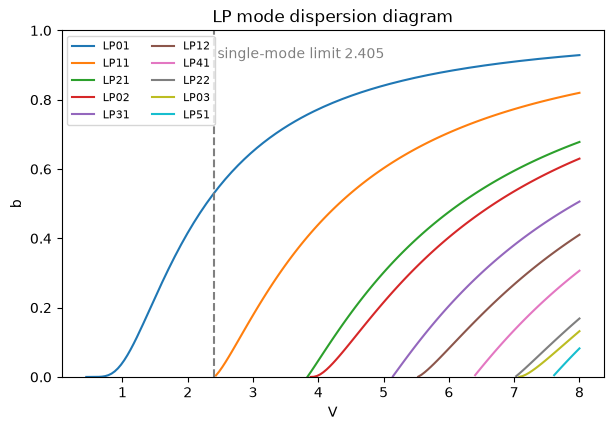

In [2]:
fib = fm.StepIndexFiber(radius=1.0, n_core=1.46, n_clad=1.45)   # radius arbitrary; we sweep V
V_grid = np.linspace(0.3, 8, 160)
curves = {}
for V in V_grid:
    lam = 2 * np.pi * fib.radius * fib.na / V
    for md in fib.modes(lam):
        curves.setdefault(md.name, []).append((V, md.b))

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, pts in sorted(curves.items(), key=lambda kv: kv[1][0][0]):
    pts = np.array(pts)
    ax.plot(pts[:, 0], pts[:, 1], label=name)
ax.axvline(fm.cutoff_v(1, 1), ls="--", c="gray")
ax.text(fm.cutoff_v(1, 1) + 0.05, 0.92, "single-mode limit 2.405", color="gray")
ax.set(xlabel="V", ylabel="b", ylim=(0, 1), title="LP mode dispersion diagram")
ax.legend(ncol=2, fontsize=8)
plt.show()

## 2. An SMF-28-like fibre

In [3]:
smf = fm.StepIndexFiber(radius=4.1, n_core=1.4504, n_clad=1.4447)
print(f"NA = {smf.na:.4f}")
print(f"single-mode cut-off wavelength = {smf.single_mode_cutoff()*1e3:.0f} nm")
for lam in (0.85, 1.31, 1.55):
    names = ", ".join(m.name for m in smf.modes(lam))
    V = smf.V(lam)
    print(f"{lam*1e3:5.0f} nm: V = {V:.3f}, modes = {names}, "
          f"MFD (Marcuse) = {fm.marcuse_mfd(V, smf.radius):.2f} um")

NA = 0.1285
single-mode cut-off wavelength = 1376 nm
  850 nm: V = 3.893, modes = LP01, LP11, LP21, LP02, MFD (Marcuse) = 7.06 um
 1310 nm: V = 2.526, modes = LP01, LP11, MFD (Marcuse) = 8.73 um
 1550 nm: V = 2.135, modes = LP01, MFD (Marcuse) = 9.83 um


## 3. Mode count of a multimode fibre

For large V the number of guided field patterns approaches $V^2/2$.

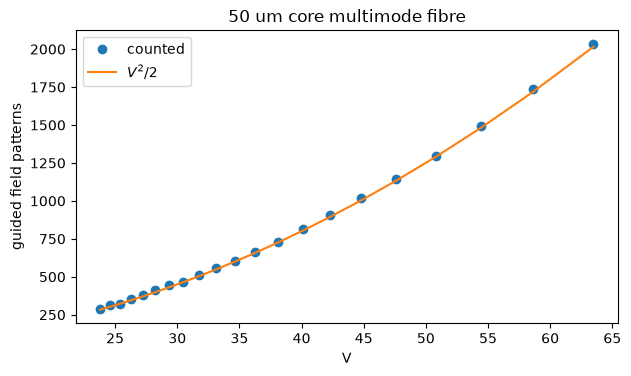

In [4]:
mmf = fm.StepIndexFiber(radius=25.0, n_core=1.48, n_clad=1.46)
lams = np.linspace(0.6, 1.6, 21)
counts = [mmf.mode_count(l) for l in lams]
Vs = np.array([mmf.V(l) for l in lams])
plt.figure(figsize=(7, 3.8))
plt.plot(Vs, counts, "o", label="counted")
plt.plot(Vs, Vs**2 / 2, label="$V^2/2$")
plt.xlabel("V"); plt.ylabel("guided field patterns"); plt.legend(); plt.title("50 um core multimode fibre")
plt.show()

## 4. Material dispersion of fused silica

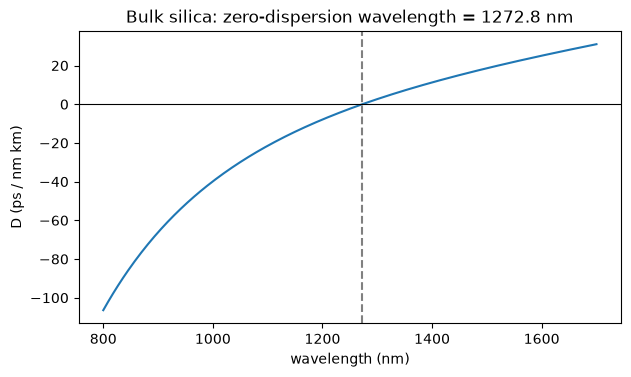

D(1550 nm) = 21.91 ps/(nm km), group index = 1.4626


In [5]:
lam = np.linspace(0.8, 1.7, 300)
D = fm.material_dispersion(lam)
zdw = fm.zero_dispersion_wavelength()
plt.figure(figsize=(7, 3.8))
plt.plot(lam * 1e3, D)
plt.axhline(0, c="k", lw=0.8); plt.axvline(zdw * 1e3, ls="--", c="gray")
plt.xlabel("wavelength (nm)"); plt.ylabel("D (ps / nm km)")
plt.title(f"Bulk silica: zero-dispersion wavelength = {zdw*1e3:.1f} nm")
plt.show()
print(f"D(1550 nm) = {float(fm.material_dispersion(1.55)):.2f} ps/(nm km), "
      f"group index = {float(fm.group_index(1.55)):.4f}")